# Bike Demand Predictor: Data Exploration and Prototyping

This notebook serves as the experimental playground. We use it to understand the data, test feature engineering ideas, and prototype the model architecture. Once a technique is proven here, it is moved into the `bike_demand_predictor/` source package for production use.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from pathlib import Path

from bike_demand_predictor.dataset import load_raw_data, split_time_series_data
from bike_demand_predictor.features import get_preprocessor
from bike_demand_predictor.modeling.train import BikeDemandANN
from bike_demand_predictor.config import TARGET_COLUMN, DEFAULT_LR, DEFAULT_BATCH_SIZE

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

### Step 1: Imports and Configuration

**What:** We import standard DS libraries and our own project modules.

**Why:** By importing from `bike_demand_predictor`, we ensure that the logic we use in this notebook is exactly the same logic that will be used in the final production pipeline. This prevents "notebook-to-production" drift.

In [3]:
df = load_raw_data()
print(f"Dataset loaded. Shape: {df.shape}")
df.head()

Dataset loaded. Shape: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


### Step 2: Loading Data

**What:** We use the `load_raw_data` helper to bring the CSV into a DataFrame.

**Why:** Centralizing data loading in `dataset.py` allows us to change the data source (e.g., moving from a CSV to a SQL database) in one place without updating every notebook or script in the project.

In [4]:
df.sample(5, random_state=42)

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
12830,12831,2012-06-23,3,1,6,19,0,6,0,1,0.80,0.6970,0.27,0.1940,185,240,425
8688,8689,2012-01-02,1,1,1,20,1,1,0,1,0.24,0.2273,0.41,0.2239,5,83,88
7091,7092,2011-10-28,4,0,10,2,0,5,1,1,0.32,0.3030,0.66,0.2836,1,3,4
12230,12231,2012-05-29,2,1,5,19,0,2,1,1,0.78,0.7121,0.52,0.3582,69,457,526
431,432,2011-01-20,1,0,1,0,0,4,1,1,0.26,0.2273,0.56,0.3881,5,8,13


### Step 3: Data Sampling

**What:** Looking at a random sample of the data.

**Why:** `head()` only shows the start of the file. Sampling helps us see if there are patterns or anomalies throughout the entire dataset.

In [5]:
df.info()
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.3 MB


,count,mean,std,min,25%,50%,75%,max
instant,17379.0,8690.000000,5017.029500,1.00,4345.5000,8690.0000,13034.5000,17379.0000
season,17379.0,2.501640,1.106918,1.00,2.0000,3.0000,3.0000,4.0000
yr,17379.0,0.502561,0.500008,0.00,0.0000,1.0000,1.0000,1.0000
mnth,17379.0,6.537775,3.438776,1.00,4.0000,7.0000,10.0000,12.0000
hr,17379.0,11.546752,6.914405,0.00,6.0000,12.0000,18.0000,23.0000
holiday,17379.0,0.028770,0.167165,0.00,0.0000,0.0000,0.0000,1.0000
weekday,17379.0,3.003683,2.005771,0.00,1.0000,3.0000,5.0000,6.0000
workingday,17379.0,0.682721,0.465431,0.00,0.0000,1.0000,1.0000,1.0000
weathersit,17379.0,1.425283,0.639357,1.00,1.0000,1.0000,2.0000,4.0000
temp,17379.0,0.496987,0.192556,0.02,0.3400,0.5000,0.6600,1.0000


### Step 4: Descriptive Statistics

**What:** Generating a summary of data types, null counts, and statistical distributions (mean, std, quartiles).

**Why:** This allows us to quickly identify missing values, check if numeric columns are actually numeric, and spot extreme outliers (e.g., comparing min/max).

In [6]:
print("Duplicate rows:", df.duplicated().sum())
df.isnull().sum().sort_values(ascending=False)

Duplicate rows: 0


instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

### Step 5: Data Quality Check

**What:** Checking for duplicate rows and missing values.

**Why:** Duplicates can leak data from train to test, and nulls will cause most ML models to crash. We need to know these exist before proceeding to cleaning.

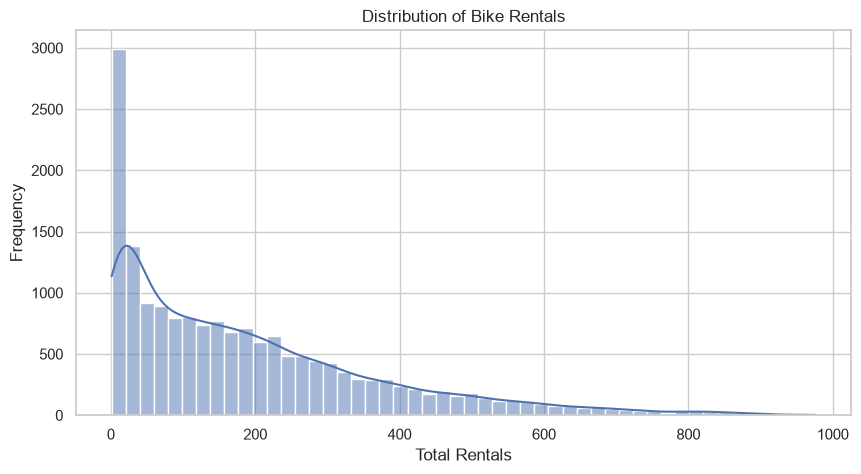

In [7]:
plt.figure(figsize=(10, 5))
sns.histplot(df[TARGET_COLUMN], bins=50, kde=True)
plt.title("Distribution of Bike Rentals")
plt.xlabel("Total Rentals")
plt.ylabel("Frequency")
plt.show()

### Step 6: Target Distribution Analysis

**What:** Plotting a histogram of the rental counts.

**Why:** To see if the target is normally distributed or skewed. Highly skewed targets often benefit from log-transformation to help the model converge better.

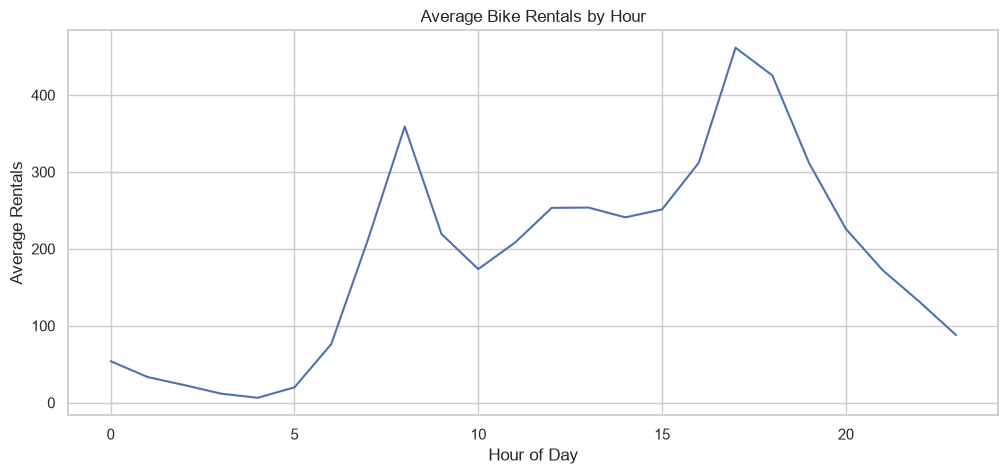

In [8]:
plt.figure(figsize=(12, 5))
sns.lineplot(data=df, x="hr", y=TARGET_COLUMN, errorbar=None)
plt.title("Average Bike Rentals by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Rentals")
plt.show()

### Step 7: Temporal Analysis (Hourly)

**What:** Analyzing how demand changes throughout the day.

**Why:** This reveals the "peaks" (usually commute hours). Knowing the signal is strong at specific hours tells us that the `hr` feature will be one of our most important predictors.

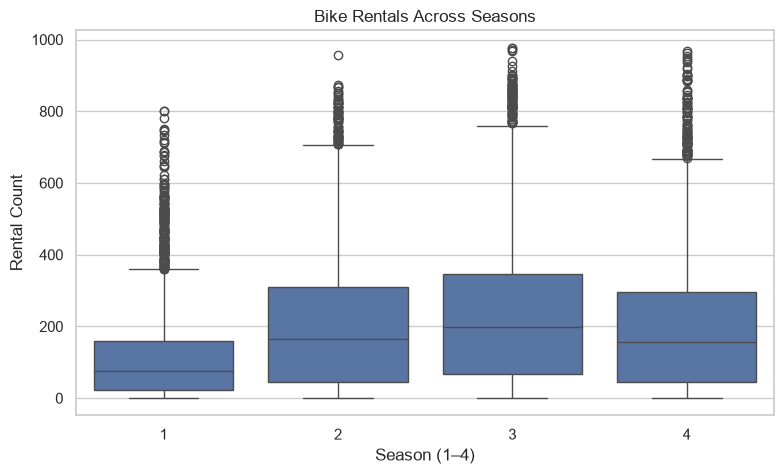

In [9]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="season", y=TARGET_COLUMN)
plt.title("Bike Rentals Across Seasons")
plt.xlabel("Season (1–4)")
plt.ylabel("Rental Count")
plt.show()

### Step 8: Seasonal Analysis

**What:** Using a boxplot to see rental distribution across the four seasons.

**Why:** This helps us understand the variance. If one season has significantly lower demand, the model needs to be able to distinguish that category clearly.

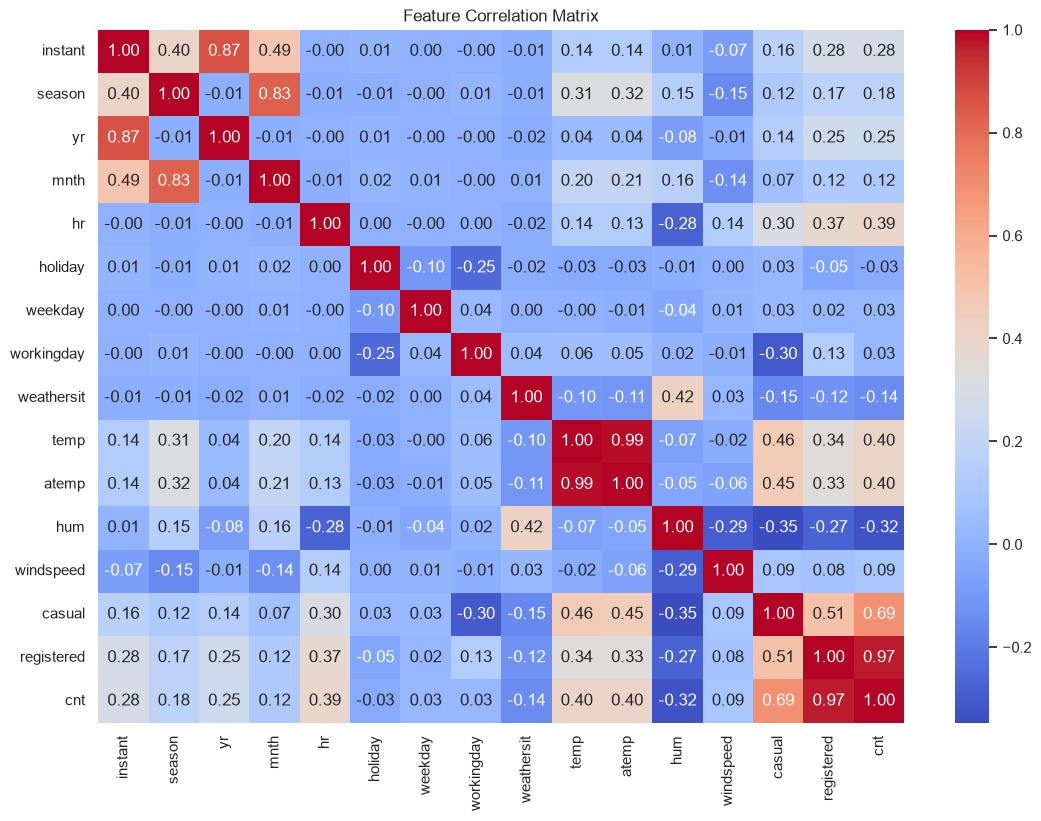

In [10]:
corr = df.corr(numeric_only=True)
plt.figure(figsize=(13, 9))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Matrix")
plt.show()

### Step 9: Correlation Analysis

**What:** Creating a heatmap of correlations between all numeric variables.

**Why:** To identify multicollinearity (two features telling the model the same thing) and to see which features have the strongest linear relationship with the target.

In [11]:
X_train, X_val, X_test, y_train, y_val, y_test = split_time_series_data(df, TARGET_COLUMN)

print(f"Train shape: {X_train.shape}")
print(f"Val shape: {X_val.shape}")
print(f"Test shape: {X_test.shape}")

Train shape: (12165, 14)
Val shape: (2607, 14)
Test shape: (2607, 14)


### Step 10: Chronological Splitting

**What:** We split the data into Training, Validation, and Testing sets using a time-based split.

**Why:** In time-series forecasting, we cannot use random splits. Using future data to predict the past (data leakage) would lead to over-optimistic results that fail in the real world. We must split the data chronologically.

In [12]:
preprocessor = get_preprocessor()

X_train_proc = preprocessor.fit_transform(X_train)
X_val_proc = preprocessor.transform(X_val)
X_test_proc = preprocessor.transform(X_test)

print(f"Processed feature shape: {X_train_proc.shape}")

Processed feature shape: (12165, 35)


### Step 11: Feature Preprocessing

**What:** We apply scaling to numeric features, one-hot encoding to categories, and cyclical encoding to hours.

**Why:** Neural networks are sensitive to scale; `StandardScaler` ensures no single feature dominates the gradient. `OneHotEncoder` handles categorical data, and cyclical encoding tells the model that hour 23 and hour 0 are close to each other.

In [13]:
# Convert to torch tensors
X_train_t = torch.tensor(X_train_proc, dtype=torch.float32)
y_train_t = torch.tensor(y_train.values, dtype=torch.float32).reshape(-1, 1)
X_val_t = torch.tensor(X_val_proc, dtype=torch.float32)
y_val_t = torch.tensor(y_val.values, dtype=torch.float32).reshape(-1, 1)

print(f"Tensor shape: {X_train_t.shape}")

Tensor shape: torch.Size([12165, 35])


### Step 12: Tensor Conversion

**What:** We convert NumPy arrays into PyTorch Tensors.

**Why:** PyTorch operations require tensors. We explicitly set `float32` because it is the default for most neural network weights and provides a good balance between precision and memory usage.

In [14]:
model = BikeDemandANN(input_features=X_train_t.shape[1])
criterion = torch.nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=DEFAULT_LR)

print(model)

BikeDemandANN(
  (network): Sequential(
    (0): Linear(in_features=35, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)


### Step 13: Model Definition

**What:** We instantiate our ANN, define the Mean Squared Error loss, and use the Adam optimizer.

**Why:** The model is defined as a class in `modeling/train.py` so we can easily change the architecture (like adding layers) without hunting through notebook cells. Adam is used as it adapts the learning rate for each parameter.

In [24]:
from pathlib import Path

Path("models").mkdir(parents=True, exist_ok=True)

In [26]:
from torch.utils.data import TensorDataset, DataLoader

train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=DEFAULT_BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val_t, y_val_t), batch_size=DEFAULT_BATCH_SIZE)

train_losses=[]
val_losses=[]

EPOCHS = 100
PATIENCE = 10

best_val_loss = float("inf")
patience_counter = 0

best_model_path = "models/best_model.pth"

for epoch in range(EPOCHS):

    # Training phase
    model.train()
    total_train_loss = 0.0

    for bx, by in train_loader:

        optimizer.zero_grad()

        predictions = model(bx)
        loss = criterion(predictions, by)

        loss.backward()
        optimizer.step()

        total_train_loss += loss.item() * bx.size(0)

    avg_train_loss = total_train_loss / len(train_loader.dataset)
    
    if avg_val_loss < best_val_loss:

        best_val_loss = avg_val_loss
        patience_counter = 0

        torch.save(model.state_dict(), best_model_path)

    else:
        patience_counter += 1

    if patience_counter >= PATIENCE:
        print("Early stopping triggered!")
        break


    # Validation phase
    model.eval()
    total_val_loss = 0.0

    with torch.no_grad():

        for bx, by in val_loader:

            predictions = model(bx)
            loss = criterion(predictions, by)

            total_val_loss += loss.item() * bx.size(0)

    avg_val_loss = total_val_loss / len(val_loader.dataset)


    # Track losses
    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f}"
    )

Epoch [1/100] Train Loss: 1033.7731 | Val Loss: 4269.4293
Epoch [2/100] Train Loss: 1031.3374 | Val Loss: 4311.4901
Epoch [3/100] Train Loss: 1019.1346 | Val Loss: 4365.2660
Epoch [4/100] Train Loss: 1014.1606 | Val Loss: 4351.4950
Epoch [5/100] Train Loss: 1009.3230 | Val Loss: 4474.7529
Epoch [6/100] Train Loss: 1013.2148 | Val Loss: 4234.8498
Epoch [7/100] Train Loss: 1000.6472 | Val Loss: 4250.7101
Epoch [8/100] Train Loss: 997.5368 | Val Loss: 4129.5886
Epoch [9/100] Train Loss: 1000.7802 | Val Loss: 4141.7650
Epoch [10/100] Train Loss: 980.7918 | Val Loss: 4388.3146
Epoch [11/100] Train Loss: 981.3840 | Val Loss: 4134.0662
Epoch [12/100] Train Loss: 972.9650 | Val Loss: 4304.1138
Epoch [13/100] Train Loss: 978.8420 | Val Loss: 4420.8388
Epoch [14/100] Train Loss: 971.0725 | Val Loss: 4087.2541
Epoch [15/100] Train Loss: 959.9389 | Val Loss: 4074.7323
Epoch [16/100] Train Loss: 959.6287 | Val Loss: 4207.0333
Epoch [17/100] Train Loss: 960.9200 | Val Loss: 4159.0905
Epoch [18/100] 

In [27]:
model.load_state_dict(
    torch.load(best_model_path, weights_only=True)
)

print("Best model restored!")

Best model restored!


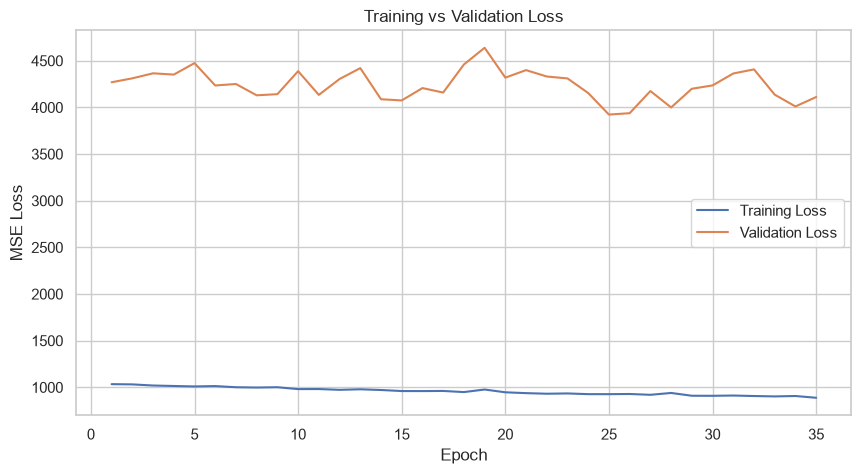

In [28]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(train_losses) + 1),
    train_losses,
    label="Training Loss"
)

plt.plot(
    range(1, len(val_losses) + 1),
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training vs Validation Loss")

plt.legend()
plt.grid(True)
plt.show()

In [29]:
best_epoch = np.argmin(val_losses) + 1
best_val_loss = min(val_losses)

print("Best epoch:", best_epoch)
print("Best validation MSE:", best_val_loss)
print("Best validation RMSE:", np.sqrt(best_val_loss))

Best epoch: 25
Best validation MSE: 3922.985734021385
Best validation RMSE: 62.63374277513188


In [ ]:
print(f"Final Training MSE: {train_losses[-1]:.2f}")
print(f"Final Validation MSE: {val_losses[-1]:.2f}")

print(f"Final Training RMSE: {train_losses[-1] ** 0.5:.2f}")
print(f"Final Validation RMSE: {val_losses[-1] ** 0.5:.2f}")

Final Training MSE: 887.87
Final Validation MSE: 4111.17
Final Training RMSE: 29.80
Final Validation RMSE: 64.12


: 

### Step 14: Training Loop

**What:** We use `DataLoader` to feed the model in batches and run a basic training loop.

**Why:** Training on the full dataset at once (Batch Gradient Descent) is memory-intensive and can get stuck in local minima. Mini-batch SGD (via DataLoader) is more computationally efficient and often leads to better convergence.